# Scenario - 3 Past Power + Past Exogenous inputs + Future Exogenous variables

Imports, paths, artifact locations, and configuration variables are defined in the next cell.

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model


# 1. Monsoon Scenario 3 configuration
SEASON = "Monsoon"
SCENARIO = "S3"
SEED = 42

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
NOTEBOOK_DIR = PROJECT_DIR / "Notebooks"

DATA_DIR = (
    PROJECT_DIR
    / "OneDrive_2026-08-26"
    / "Solar Profile Dataset"
    / SEASON
)

TRAIN_PATH = DATA_DIR / "Monsoon_Train.xlsx"
VALIDATION_PATH = DATA_DIR / "Monsoon_Val.xlsx"
TEST_PATH = DATA_DIR / "Monsoon_Test.xlsx"

TEST_START = pd.Timestamp("2025-10-08")
TEST_END_EXCLUSIVE = pd.Timestamp("2025-10-15")
HISTORY_DAY = TEST_START - pd.Timedelta(days=1)


# 2. Revision and forecast settings
REVISION_LENGTHS = {
    "R0": 32,
    "R1": 50,
    "R2": 64,
    "R3": 82,
}

BLOCKS_PER_DAY = 96
TARGET_LENGTH = 96
PADDED_INPUT_LENGTH = max(REVISION_LENGTHS.values())

PAD_VALUE = -1.0
MASK_VALUE = PAD_VALUE
POWER_COLUMN = "Act. Power (MW)"


# 3. Preserve the S3 feature selection and order across seasons.
PAST_EXOG_COLUMNS = [
    "W-MODT- (°C)",
    "W-GHI (W/m2)",
    "W-AMBT (°C)",
    "W-WDIR-   (Degree)",
]

SELECTED_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
]
FUTURE_EXOG_COLUMNS = SELECTED_FUTURE_EXOG_COLUMNS.copy()

HISTORY_COLUMNS = [POWER_COLUMN] + PAST_EXOG_COLUMNS
INPUT_FEATURES = HISTORY_COLUMNS + ["sin(time)", "cos(time)"]

N_HISTORY_FEATURES = len(INPUT_FEATURES)       # 7
N_FUTURE_EXOG = len(FUTURE_EXOG_COLUMNS)       # 3
N_FUTURE_FEATURES = N_FUTURE_EXOG + 2          # 5


# 4. Separate Monsoon S3 checkpoints
artifact_dir = NOTEBOOK_DIR / "Saved_Models" / SEASON / SCENARIO
model_path = artifact_dir / "monsoon_s3_encoder_decoder.keras"
preprocessing_path = artifact_dir / "monsoon_s3_preprocessing.joblib"
scaler_path = preprocessing_path


# 5. Output folders
results_dir = NOTEBOOK_DIR / "Results" / SEASON
prediction_dir = results_dir / "Predictions"
timing_dir = results_dir / "Timing"

prediction_path = prediction_dir / f"{SEASON}_Daily_RNN_{SCENARIO}.csv"
results_path = prediction_path
timing_summary_path = timing_dir / f"{SEASON}_RNN_Computation_Times.csv"

for path in (TRAIN_PATH, VALIDATION_PATH, TEST_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Dataset file not found: {path}")

for folder in (artifact_dir, results_dir, prediction_dir, timing_dir):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Configuration: {SEASON} — {SCENARIO}")
print("Test target dates: October 8–14, 2025")
print("Historical measurements:", HISTORY_COLUMNS)
print("Future weather inputs:", FUTURE_EXOG_COLUMNS)
print(f"History channels: {N_HISTORY_FEATURES}")
print(f"Future channels: {N_FUTURE_FEATURES}")
print(f"Model: {model_path}")
print(f"Predictions: {prediction_path}")

Configuration: Monsoon — S3
Test target dates: October 8–14, 2025
Historical measurements: ['Act. Power (MW)', 'W-MODT- (°C)', 'W-GHI (W/m2)', 'W-AMBT (°C)', 'W-WDIR-   (Degree)']
Future weather inputs: ['W-GHI (W/m2)', 'W-WDIR-   (Degree)', 'W-WSPD (m/s)']
History channels: 7
Future channels: 5
Model: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Saved_Models\Monsoon\S3\monsoon_s3_encoder_decoder.keras
Predictions: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Monsoon\Predictions\Monsoon_Daily_RNN_S3.csv


# 2. Load Dataset

Load the existing chronological Excel datasets and inspect their row/day counts. No raw data or split files are changed.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

SEASON = "Monsoon"
SCENARIO = "S3"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
DATA_DIR = (
    PROJECT_DIR
    / "OneDrive_2026-08-26"
    / "Solar Profile Dataset"
    / SEASON
)

TRAIN_PATH = DATA_DIR / "Monsoon_Train.xlsx"
VALIDATION_PATH = DATA_DIR / "Monsoon_Val.xlsx"
TEST_PATH = DATA_DIR / "Monsoon_Test.xlsx"

TEST_START = pd.Timestamp("2025-10-08")
TEST_END_EXCLUSIVE = pd.Timestamp("2025-10-15")
HISTORY_DAY = TEST_START - pd.Timedelta(days=1)

POWER_COLUMN = "Act. Power (MW)"

# Preserve the same S3 feature selection across seasons.
PAST_EXOG_COLUMNS = [
    "W-MODT- (°C)",
    "W-GHI (W/m2)",
    "W-AMBT (°C)",
    "W-WDIR-   (Degree)",
]
SELECTED_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
]
FUTURE_EXOG_COLUMNS = SELECTED_FUTURE_EXOG_COLUMNS.copy()
HISTORY_COLUMNS = [POWER_COLUMN] + PAST_EXOG_COLUMNS

REQUIRED_MEASUREMENTS = list(dict.fromkeys(
    HISTORY_COLUMNS + FUTURE_EXOG_COLUMNS
))


def normalize_header(name):
    return " ".join(str(name).split())


def load_data(train_path, validation_path, test_path):
    """Load your manual splits directly without reassigning any rows."""
    splits = []

    for path in (train_path, validation_path, test_path):
        path = Path(path)
        data = pd.read_excel(path)

        if data.empty:
            raise ValueError(f"{path.name}: empty dataset.")

        # Resolve extra spaces while preserving the expected feature names.
        lookup = {}
        for column in data.columns:
            key = normalize_header(column)
            if key in lookup:
                raise ValueError(
                    f"{path.name}: ambiguous column headers: {key}"
                )
            lookup[key] = column

        required = ["TimeStamp", *REQUIRED_MEASUREMENTS]
        missing = [
            name for name in required
            if normalize_header(name) not in lookup
        ]
        if missing:
            raise ValueError(f"{path.name}: missing columns: {missing}")

        data = data.rename(columns={
            lookup[normalize_header(name)]: name
            for name in required
        })

        timestamps = pd.to_datetime(
            data["TimeStamp"], errors="raise"
        )
        if timestamps.isna().any():
            raise ValueError(f"{path.name}: missing timestamps.")

        # Correct only the previously verified small timestamp drift.
        # Excel files and row assignments remain unchanged.
        corrected_times = timestamps.dt.round("15min")
        adjustments = (
            corrected_times - timestamps
        ).abs().dt.total_seconds()

        if adjustments.max() > 10.0:
            raise ValueError(
                f"{path.name}: timestamp adjustment exceeds 10 seconds. "
                "Inspect timestamps before rounding."
            )

        if corrected_times.duplicated().any():
            raise ValueError(
                f"{path.name}: duplicate timestamps after rounding."
            )

        data["TimeStamp"] = corrected_times
        data = data.sort_values("TimeStamp").reset_index(drop=True)
        data["Date"] = data["TimeStamp"].dt.date

        for column in REQUIRED_MEASUREMENTS:
            data[column] = pd.to_numeric(data[column], errors="raise")

        if not np.isfinite(
            data[REQUIRED_MEASUREMENTS].to_numpy(dtype=np.float64)
        ).all():
            raise ValueError(
                f"{path.name}: required measurements contain "
                "missing or infinite values."
            )

        print(
            f"{path.name}: corrected {(adjustments > 0).sum():,} timestamps; "
            f"maximum adjustment {adjustments.max():.3f} seconds"
        )

        splits.append(data)

    return tuple(splits)


def check_split(data, name, first_day, last_day):
    """Require a complete, unique 15-minute block-start grid."""
    expected = pd.date_range(
        start=first_day,
        end=pd.Timestamp(last_day) + pd.Timedelta(hours=23, minutes=45),
        freq="15min",
    )
    observed = pd.DatetimeIndex(data["TimeStamp"])

    if not observed.equals(expected):
        raise ValueError(
            f"{name}: expected {first_day} through {last_day}, "
            f"with {len(expected)} rows; found {len(data)}.\n"
            f"First missing blocks: {expected.difference(observed)[:5].tolist()}\n"
            f"First unexpected blocks: {observed.difference(expected)[:5].tolist()}"
        )

    print(
        f"{name}: {data['Date'].nunique()} days | "
        f"{len(data):,} rows | {observed[0]} → {observed[-1]}"
    )


# Load the three manually split files directly.
train, validation, test = load_data(
    TRAIN_PATH,
    VALIDATION_PATH,
    TEST_PATH,
)

check_split(train, "Training", "2025-06-15", "2025-09-08")
check_split(validation, "Validation", "2025-09-09", "2025-10-07")
check_split(test, "Test targets", "2025-10-08", "2025-10-14")

# October 7 supplies historical inputs for the October 8 forecast.
history_rows = validation.loc[
    validation["Date"].eq(HISTORY_DAY.date())
].copy()

# Use only required columns so unrelated Excel columns may differ.
sample_columns = ["TimeStamp", "Date", *REQUIRED_MEASUREMENTS]

test_with_history = pd.concat(
    [
        history_rows.loc[:, sample_columns],
        test.loc[:, sample_columns],
    ],
    ignore_index=True,
).sort_values("TimeStamp", ignore_index=True)

check_split(
    test_with_history,
    "Test including history",
    "2025-10-07",
    "2025-10-14",
)

print("\nMonsoon S3 expected samples:")
print("Training   : 85 target days × 4 = 340")
print("Validation : 28 target days × 4 = 112")
print("Test       :  7 target days × 4 = 28")
print("\nUse test_with_history for test sample creation.")
print("No rows reassigned between splits. No Excel files modified.")

Monsoon_Train.xlsx: corrected 1,746 timestamps; maximum adjustment 8.735 seconds
Monsoon_Val.xlsx: corrected 0 timestamps; maximum adjustment 0.000 seconds
Monsoon_Test.xlsx: corrected 0 timestamps; maximum adjustment 0.000 seconds
Training: 86 days | 8,256 rows | 2025-06-15 00:00:00 → 2025-09-08 23:45:00
Validation: 29 days | 2,784 rows | 2025-09-09 00:00:00 → 2025-10-07 23:45:00
Test targets: 7 days | 672 rows | 2025-10-08 00:00:00 → 2025-10-14 23:45:00
Test including history: 8 days | 768 rows | 2025-10-07 00:00:00 → 2025-10-14 23:45:00

Monsoon S3 expected samples:
Training   : 85 target days × 4 = 340
Validation : 28 target days × 4 = 112
Test       :  7 target days × 4 = 28

Use test_with_history for test sample creation.
No rows reassigned between splits. No Excel files modified.


# 3. Train / Validation / Test Split

The notebook uses the existing chronological Excel splits without re-splitting or shuffling the datasets.

# 4. Revision Sample Creation

Put the existing revision lengths, target length, padded input length, sample creator, and train/validation/test sample creation in this section.

In [4]:
import numpy as np
import pandas as pd

REVISION_LENGTHS = {
    "R0": 32,
    "R1": 50,
    "R2": 64,
    "R3": 82,
}

TARGET_LENGTH = 96
BLOCKS_PER_DAY = 96
PADDED_INPUT_LENGTH = max(REVISION_LENGTHS.values())
POWER_COLUMN = "Act. Power (MW)"
MASK_VALUE = -1.0
PAD_VALUE = MASK_VALUE

# Preserve the same S3 feature order across seasons.
PAST_EXOG_COLUMNS = [
    "W-MODT- (°C)",
    "W-GHI (W/m2)",
    "W-AMBT (°C)",
    "W-WDIR-   (Degree)",
]
HISTORY_COLUMNS = [POWER_COLUMN] + PAST_EXOG_COLUMNS

SELECTED_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
]
FUTURE_EXOG_COLUMNS = SELECTED_FUTURE_EXOG_COLUMNS.copy()

# Clock features are added in preprocessing.
N_HISTORY_FEATURES = len(HISTORY_COLUMNS) + 2
N_FUTURE_EXOG = len(FUTURE_EXOG_COLUMNS)
N_FUTURE_FEATURES = N_FUTURE_EXOG + 2

if POWER_COLUMN in FUTURE_EXOG_COLUMNS:
    raise ValueError("Future actual power cannot be an input feature.")


def normalize_header(name):
    return " ".join(str(name).split())


def resolve_columns(data, names):
    lookup = {}

    for column in data.columns:
        key = normalize_header(column)
        if key in lookup:
            raise ValueError(f"Ambiguous column headers: {key}")
        lookup[key] = column

    missing = [
        name for name in names
        if normalize_header(name) not in lookup
    ]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    return [lookup[normalize_header(name)] for name in names]


def create_revision_samples(split, split_name="Split"):
    """Create unscaled D → D+1 samples for Monsoon S3."""
    data = split.copy()
    data["TimeStamp"] = pd.to_datetime(
        data["TimeStamp"], errors="raise"
    )
    data = data.sort_values("TimeStamp").reset_index(drop=True)

    timestamps = data["TimeStamp"]
    if timestamps.isna().any() or timestamps.duplicated().any():
        raise ValueError(f"{split_name}: missing or duplicate timestamps.")

    if not timestamps.eq(timestamps.dt.floor("15min")).all():
        raise ValueError(
            f"{split_name}: timestamps are off the 15-minute grid. "
            "Run the Monsoon loading cell first."
        )

    data["Date"] = timestamps.dt.date

    history_cols = resolve_columns(data, HISTORY_COLUMNS)
    future_cols = resolve_columns(data, FUTURE_EXOG_COLUMNS)
    power_col = resolve_columns(data, [POWER_COLUMN])[0]

    for column in dict.fromkeys(history_cols + future_cols):
        data[column] = pd.to_numeric(data[column], errors="raise")

    day_groups = {
        day: rows.set_index("TimeStamp")
        for day, rows in data.groupby("Date", sort=True)
    }

    X, X_future, y = [], [], []
    revision_labels, sample_dates = [], []
    revision_indices = {
        revision: [] for revision in REVISION_LENGTHS
    }

    for day, day_data in day_groups.items():
        next_day = (pd.Timestamp(day) + pd.Timedelta(days=1)).date()
        target_data = day_groups.get(next_day)

        if target_data is None:
            continue

        history_grid = pd.date_range(
            day, periods=PADDED_INPUT_LENGTH, freq="15min"
        )
        target_grid = pd.date_range(
            next_day, periods=TARGET_LENGTH, freq="15min"
        )

        if not history_grid.isin(day_data.index).all():
            raise ValueError(f"{split_name}: incomplete history on {day}.")

        if not target_data.index.equals(target_grid):
            raise ValueError(
                f"{split_name}: incomplete target day {next_day}."
            )

        history = day_data.loc[
            history_grid, history_cols
        ].to_numpy(dtype=np.float32)

        future_exog = target_data.loc[
            target_grid, future_cols
        ].to_numpy(dtype=np.float32)

        target = target_data.loc[
            target_grid, power_col
        ].to_numpy(dtype=np.float32)

        for name, values in (
            ("history", history),
            ("future weather", future_exog),
            ("target power", target),
        ):
            if not np.isfinite(values).all():
                raise ValueError(
                    f"{split_name}: nonfinite {name} in {day} → {next_day}."
                )

        for revision, length in REVISION_LENGTHS.items():
            revision_indices[revision].append(len(X))
            X.append(history[:length].copy())
            X_future.append(future_exog.copy())
            y.append(target.copy())
            revision_labels.append(revision)
            sample_dates.append(next_day)

    if not X:
        raise ValueError(f"{split_name}: no consecutive-day samples.")

    return (
        X,
        np.stack(X_future),
        np.stack(y),
        np.asarray(revision_labels),
        revision_indices,
        np.asarray(sample_dates),
    )


# Use the manually split dataframes from the loading cell.
(
    X_train,
    X_future_train,
    y_train,
    revision_labels_train,
    revision_indices_train,
    dates_train,
) = create_revision_samples(train, "Train")

(
    X_validation,
    X_future_validation,
    y_validation,
    revision_labels_validation,
    revision_indices_validation,
    dates_validation,
) = create_revision_samples(validation, "Validation")

# October 7 supplies history; October 8–14 are test target days.
(
    X_test,
    X_future_test,
    y_test,
    revision_labels_test,
    revision_indices_test,
    dates_test,
) = create_revision_samples(test_with_history, "Test")


# Verify exact target dates and all four revisions.
expected_ranges = {
    "Train": ("2025-06-16", "2025-09-08"),
    "Validation": ("2025-09-10", "2025-10-07"),
    "Test": ("2025-10-08", "2025-10-14"),
}

for name, histories, future, targets, labels, dates in (
    (
        "Train", X_train, X_future_train, y_train,
        revision_labels_train, dates_train,
    ),
    (
        "Validation", X_validation, X_future_validation, y_validation,
        revision_labels_validation, dates_validation,
    ),
    (
        "Test", X_test, X_future_test, y_test,
        revision_labels_test, dates_test,
    ),
):
    first_day, last_day = expected_ranges[name]
    expected_days = pd.date_range(first_day, last_day, freq="D")

    expected_pairs = pd.MultiIndex.from_product(
        [expected_days.date, list(REVISION_LENGTHS)]
    )
    actual_pairs = pd.MultiIndex.from_arrays([dates, labels])

    if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
        raise ValueError(f"{name}: unexpected target dates or revisions.")

    n_samples = len(expected_pairs)

    if len(histories) != n_samples:
        raise ValueError(f"{name}: incorrect history count.")

    if targets.shape != (n_samples, TARGET_LENGTH):
        raise ValueError(f"{name}: incorrect target shape.")

    if future.shape != (
        n_samples, TARGET_LENGTH, len(FUTURE_EXOG_COLUMNS)
    ):
        raise ValueError(f"{name}: incorrect future-weather shape.")

    for history, revision in zip(histories, labels):
        expected_shape = (
            REVISION_LENGTHS[revision], len(HISTORY_COLUMNS)
        )
        if history.shape != expected_shape:
            raise ValueError(
                f"{name}, {revision}: expected history shape "
                f"{expected_shape}, received {history.shape}."
            )

    print(
        f"{name}: {len(expected_days)} target days | "
        f"{n_samples} samples"
    )
    print(f"  Raw history shapes: {[x.shape for x in histories[:4]]}")
    print(f"  Future weather: {future.shape}")
    print(f"  Targets: {targets.shape}")


target_date_sets = [
    set(dates_train),
    set(dates_validation),
    set(dates_test),
]
if any(
    target_date_sets[i] & target_date_sets[j]
    for i, j in ((0, 1), (0, 2), (1, 2))
):
    raise ValueError("Target dates overlap across splits.")

revision_info = {
    "lengths": REVISION_LENGTHS.copy(),
    "train": revision_indices_train,
    "validation": revision_indices_validation,
    "test": revision_indices_test,
}

test_dates = sorted(set(dates_test))


# Night-mask source: all 86 complete raw Monsoon training days.
# Includes June 15, which does not appear as a training target day.
training_data = train.copy()
training_data["TimeStamp"] = pd.to_datetime(
    training_data["TimeStamp"], errors="raise"
)
training_data = training_data.sort_values(
    "TimeStamp", ignore_index=True
)

expected_training_grid = pd.date_range(
    "2025-06-15 00:00",
    "2025-09-08 23:45",
    freq="15min",
)

if not pd.DatetimeIndex(
    training_data["TimeStamp"]
).equals(expected_training_grid):
    raise ValueError(
        "Night-mask source must contain the complete training grid "
        "from June 15 through September 8, 2025."
    )

training_power_col = resolve_columns(
    training_data, [POWER_COLUMN]
)[0]

training_power = pd.to_numeric(
    training_data[training_power_col], errors="raise"
).to_numpy(dtype=np.float32)

if not np.isfinite(training_power).all():
    raise ValueError("Nonfinite power in the night-mask training data.")

nightmask_training_power = training_power.reshape(86, BLOCKS_PER_DAY)
active_fraction = (nightmask_training_power > 0.1).mean(axis=0)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)

print("\nHistorical measurements:", HISTORY_COLUMNS)
print("Selected future weather:", FUTURE_EXOG_COLUMNS)
print("Night-mask source:", nightmask_training_power.shape)
print("Monsoon S3 test: 7 target days × 4 revisions = 28 samples")

Train: 85 target days | 340 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future weather: (340, 96, 3)
  Targets: (340, 96)
Validation: 28 target days | 112 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future weather: (112, 96, 3)
  Targets: (112, 96)
Test: 7 target days | 28 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future weather: (28, 96, 3)
  Targets: (28, 96)

Historical measurements: ['Act. Power (MW)', 'W-MODT- (°C)', 'W-GHI (W/m2)', 'W-AMBT (°C)', 'W-WDIR-   (Degree)']
Selected future weather: ['W-GHI (W/m2)', 'W-WDIR-   (Degree)', 'W-WSPD (m/s)']
Night-mask source: (86, 96)
Monsoon S3 test: 7 target days × 4 revisions = 28 samples


# 5. Preprocessing and Scaling

This section preserves the existing `MinMaxScaler`, time features, padding, and scaled input creation.

In [5]:
from sklearn.preprocessing import MinMaxScaler

# Resolve extra spaces in Excel column headers.
def get_feature_values(df, columns):
    normalize = lambda name: ' '.join(str(name).split())
    lookup = {normalize(col): col for col in df.columns}
    actual_columns = [lookup[normalize(col)] for col in columns]
    return df[actual_columns].to_numpy(dtype=np.float32)


# Separate scalers for target power, past exogenous, and future exogenous.
# Keep the name "scaler" for compatibility with inverse-scaling later.
scaler = MinMaxScaler()
past_exog_scaler = MinMaxScaler()
future_exog_scaler = MinMaxScaler()

scaler.fit(get_feature_values(train, [POWER_COLUMN]))
past_exog_scaler.fit(get_feature_values(train, PAST_EXOG_COLUMNS))
future_exog_scaler.fit(get_feature_values(train, FUTURE_EXOG_COLUMNS))

train_power_scaled = scaler.transform(
    get_feature_values(train, [POWER_COLUMN])
)
val_power_scaled = scaler.transform(
    get_feature_values(validation, [POWER_COLUMN])
)
test_power_scaled = scaler.transform(
    get_feature_values(test, [POWER_COLUMN])
)


def time_features(block_indices):
    block_indices = np.asarray(block_indices, dtype=np.float32)
    phase = 2.0 * np.pi * block_indices / BLOCKS_PER_DAY
    return np.column_stack(
        (np.sin(phase), np.cos(phase))
    ).astype(np.float32)


N_HISTORY_FEATURES = 1 + len(PAST_EXOG_COLUMNS) + 2
N_FUTURE_FEATURES = len(FUTURE_EXOG_COLUMNS) + 2


def preprocess_revision_samples(
    X_raw, X_future_raw, y_raw, revision_labels
):
    n_samples = len(X_raw)

    assert len(revision_labels) == n_samples
    assert y_raw.shape == (n_samples, TARGET_LENGTH)
    assert X_future_raw.shape == (
        n_samples, TARGET_LENGTH, len(FUTURE_EXOG_COLUMNS)
    )

    # Every channel in padded timesteps must equal MASK_VALUE.
    X_processed = np.full(
        (n_samples, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        MASK_VALUE,
        dtype=np.float32,
    )

    # Scale real history first, then insert into padded array.
    for i, (history, revision) in enumerate(
        zip(X_raw, revision_labels)
    ):
        real_length = REVISION_LENGTHS[revision]

        assert history.shape == (
            real_length, 1 + len(PAST_EXOG_COLUMNS)
        )

        scaled_power = scaler.transform(history[:, :1])
        scaled_exog = past_exog_scaler.transform(history[:, 1:])
        temporal = time_features(np.arange(real_length))

        X_processed[i, :real_length] = np.concatenate(
            [scaled_power, scaled_exog, temporal],
            axis=-1,
        ).astype(np.float32)

    # Future inputs cover the full target day; no padding.
    future_scaled = future_exog_scaler.transform(
        X_future_raw.reshape(-1, len(FUTURE_EXOG_COLUMNS))
    ).reshape(
        n_samples, TARGET_LENGTH, len(FUTURE_EXOG_COLUMNS)
    ).astype(np.float32)

    future_time = np.broadcast_to(
        time_features(np.arange(TARGET_LENGTH))[None, :, :],
        (n_samples, TARGET_LENGTH, 2),
    )

    X_future_processed = np.concatenate(
        [future_scaled, future_time],
        axis=-1,
    ).astype(np.float32)

    y_scaled = scaler.transform(
        y_raw.reshape(-1, 1)
    ).reshape(y_raw.shape).astype(np.float32)

    return X_processed, X_future_processed, y_scaled


(
    X_train_scaled, X_future_train_scaled, y_train_scaled
) = preprocess_revision_samples(
    X_train, X_future_train, y_train, revision_labels_train
)

(
    X_validation_scaled, X_future_validation_scaled,
    y_validation_scaled
) = preprocess_revision_samples(
    X_validation, X_future_validation, y_validation,
    revision_labels_validation,
)

(
    X_test_scaled, X_future_test_scaled, y_test_scaled
) = preprocess_revision_samples(
    X_test, X_future_test, y_test, revision_labels_test
)


# Validate shapes, padding, and temporal alignment.
for split_name, X_scaled, future_scaled, y_scaled, labels in (
    (
        'Train', X_train_scaled, X_future_train_scaled,
        y_train_scaled, revision_labels_train,
    ),
    (
        'Validation', X_validation_scaled, X_future_validation_scaled,
        y_validation_scaled, revision_labels_validation,
    ),
    (
        'Test', X_test_scaled, X_future_test_scaled,
        y_test_scaled, revision_labels_test,
    ),
):
    assert X_scaled.shape == (
        len(labels), PADDED_INPUT_LENGTH, N_HISTORY_FEATURES
    )
    assert future_scaled.shape == (
        len(labels), TARGET_LENGTH, N_FUTURE_FEATURES
    )
    assert y_scaled.shape == (len(labels), TARGET_LENGTH)

    assert np.isfinite(X_scaled).all()
    assert np.isfinite(future_scaled).all()
    assert np.isfinite(y_scaled).all()

    assert np.allclose(
        future_scaled[:, :, -2:],
        time_features(np.arange(TARGET_LENGTH))[None, :, :],
    )

    for revision, real_length in REVISION_LENGTHS.items():
        revision_mask = labels == revision
        if not revision_mask.any():
            continue

        real = X_scaled[revision_mask, :real_length, :]
        padding = X_scaled[revision_mask, real_length:, :]

        assert np.all(padding == MASK_VALUE)
        assert not np.any(np.all(real == MASK_VALUE, axis=-1))
        assert np.allclose(
            real[:, :, -2:],
            time_features(np.arange(real_length))[None, :, :],
        )

    print(
        f'{split_name}: history={X_scaled.shape}, '
        f'future={future_scaled.shape}, target={y_scaled.shape}'
    )

# Keep nightmask_training_power in original MW.
# Do not mask targets or future weather inputs in this cell.
print('Preprocessing checks passed.')

Train: history=(340, 82, 7), future=(340, 96, 5), target=(340, 96)
Validation: history=(112, 82, 7), future=(112, 96, 5), target=(112, 96)
Test: history=(28, 82, 7), future=(28, 96, 5), target=(28, 96)
Preprocessing checks passed.


# 6. Reproducibility

This section must run before model creation or training.REPRODUCIBLITY

In [6]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

Reproducibility configured with seed 42.


# 7. Model Architecture

This section contains only the existing encoder-decoder model definition.

In [7]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping


def build_model(n_future_exog):
    """
    n_future_exog: number of future weather variables being tested.
    Two time channels are always included.
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name='encoder_input',
    )

    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name='encoder_masking',
    )(encoder_input)

    encoder_context = SimpleRNN(
        64,
        name='encoder_rnn',
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name='future_input',
    )

    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name='repeat_context',
    )(encoder_context)

    decoder_input = Concatenate(
        axis=-1,
        name='decoder_features',
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name='decoder_rnn',
    )(decoder_input)

    block_predictions = TimeDistributed(
        Dense(1),
        name='block_prediction',
    )(decoder_sequence)

    forecast = Reshape(
        (TARGET_LENGTH,),
        name='forecast',
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae'],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


print("Model builder ready for future-feature selection.")

Model builder ready for future-feature selection.


# 8. Model Training

**RUN ONLY WHEN TRAINING THE MODEL**  
**DO NOT RUN FOR DEMO**

In [8]:
from pathlib import Path
from time import perf_counter
from datetime import datetime
import platform

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping


# 1. Monsoon S3 configuration
SEASON = "Monsoon"
SCENARIO = "S3"
SEED = 42
BATCH_SIZE = 16
MAX_EPOCHS = 150

N_HISTORY_FEATURES = 7
MASK_VALUE = -1.0

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
timing_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Timing"
)
timing_dir.mkdir(parents=True, exist_ok=True)

# Fixed filenames: overwrite previous S3 timing and loss history.
run_path = timing_dir / f"{SEASON}_RNN_{SCENARIO}_Timing.csv"
history_path = timing_dir / f"{SEASON}_RNN_{SCENARIO}_History.csv"
summary_path = timing_dir / f"{SEASON}_RNN_Computation_Times.csv"

SELECTED_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
]

# FUTURE_EXOG_COLUMNS must match the channel order used in preprocessing.
source_columns = list(FUTURE_EXOG_COLUMNS)


def normalize_feature_name(name):
    return " ".join(str(name).split())


normalized_source = [
    normalize_feature_name(column) for column in source_columns
]
if len(set(normalized_source)) != len(normalized_source):
    raise ValueError("Ambiguous future-weather column names.")

missing = [
    column for column in SELECTED_FUTURE_EXOG_COLUMNS
    if normalize_feature_name(column) not in normalized_source
]
if missing:
    raise ValueError(f"Missing future weather columns: {missing}")

selected_indices = [
    normalized_source.index(normalize_feature_name(column))
    for column in SELECTED_FUTURE_EXOG_COLUMNS
] + [len(source_columns), len(source_columns) + 1]


# 2. Select three weather channels followed by time sine/cosine.
def select_s3_future(full_inputs):
    full_inputs = np.asarray(full_inputs)

    if (
        full_inputs.ndim != 3
        or full_inputs.shape[1:] != (
            TARGET_LENGTH, len(source_columns) + 2
        )
    ):
        raise ValueError(
            f"Unexpected future input shape: {full_inputs.shape}"
        )

    return full_inputs[:, :, selected_indices].astype(np.float32)


benchmark_future_train = select_s3_future(X_future_train_scaled)
benchmark_future_validation = select_s3_future(
    X_future_validation_scaled
)
benchmark_future_test = select_s3_future(X_future_test_scaled)

# Compatibility with later prediction cells.
X_future_train_selected = benchmark_future_train
X_future_validation_selected = benchmark_future_validation
X_future_test_selected = benchmark_future_test

for name, X, future, y, expected_samples in (
    (
        "Train", X_train_scaled,
        benchmark_future_train, y_train_scaled, 340,
    ),
    (
        "Validation", X_validation_scaled,
        benchmark_future_validation, y_validation_scaled, 112,
    ),
    (
        "Test", X_test_scaled,
        benchmark_future_test, y_test_scaled, 28,
    ),
):
    if X.shape != (expected_samples, PADDED_INPUT_LENGTH, 7):
        raise ValueError(f"{name}: unexpected history shape {X.shape}.")

    if future.shape != (expected_samples, TARGET_LENGTH, 5):
        raise ValueError(f"{name}: unexpected future shape {future.shape}.")

    if y.shape != (expected_samples, TARGET_LENGTH):
        raise ValueError(f"{name}: unexpected target shape {y.shape}.")

    if not all(np.isfinite(values).all() for values in (X, future, y)):
        raise ValueError(f"{name}: missing or infinite values.")


# Verify October 8–14, with exactly one sample per revision and date.
test_days = pd.date_range("2025-10-08", "2025-10-14", freq="D")
expected_pairs = pd.MultiIndex.from_product(
    [test_days, list(REVISION_LENGTHS)]
)
actual_pairs = pd.MultiIndex.from_arrays([
    pd.DatetimeIndex(pd.to_datetime(dates_test)).normalize(),
    np.asarray(revision_labels_test),
])

if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError(
        "Expected exactly one R0–R3 sample per day for October 8–14, 2025."
    )


# 3. Build fresh weights using the shared architecture.
# Rerunning this cell starts a new training run.
benchmark_model = build_model(
    n_future_exog=len(SELECTED_FUTURE_EXOG_COLUMNS)
)

if benchmark_model.input_shape != [
    (None, PADDED_INPUT_LENGTH, 7),
    (None, TARGET_LENGTH, 5),
] or benchmark_model.output_shape != (None, TARGET_LENGTH):
    raise ValueError("Model dimensions do not match Monsoon S3.")


# 4. Measure validation passes inside fit().
class ValidationTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.validation_seconds = 0.0
        self.validation_passes = 0

    def on_test_begin(self, logs=None):
        self.validation_start = perf_counter()

    def on_test_end(self, logs=None):
        self.validation_seconds += (
            perf_counter() - self.validation_start
        )
        self.validation_passes += 1


timer = ValidationTimer()
early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=15,
    restore_best_weights=True,
)


# 5. Time training and internal validation.
fit_start = perf_counter()

benchmark_history = benchmark_model.fit(
    [X_train_scaled, benchmark_future_train],
    y_train_scaled,
    validation_data=(
        [X_validation_scaled, benchmark_future_validation],
        y_validation_scaled,
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=[early_stopping, timer],
    verbose=1,
)

fit_seconds = perf_counter() - fit_start
validation_seconds = timer.validation_seconds

# Includes training and remaining fit/callback overhead.
training_seconds = fit_seconds - validation_seconds

model = benchmark_model
history = benchmark_history
training_history = benchmark_history.history

validation_losses = np.asarray(
    training_history["val_loss"], dtype=np.float64
)
if (
    validation_losses.size == 0
    or not np.isfinite(validation_losses).all()
):
    raise ValueError("Invalid validation losses.")

best_epoch = int(np.argmin(validation_losses)) + 1


# 6. Time the first test prediction call.
test_start = perf_counter()

benchmark_predictions_scaled = model.predict(
    [X_test_scaled, benchmark_future_test],
    batch_size=BATCH_SIZE,
    verbose=0,
)

testing_seconds = perf_counter() - test_start
overall_seconds = fit_seconds + testing_seconds

if (
    benchmark_predictions_scaled.shape != (28, TARGET_LENGTH)
    or not np.isfinite(benchmark_predictions_scaled).all()
):
    raise ValueError("Invalid test predictions.")


# 7. Prepare timing metadata.
run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
gpu_devices = tf.config.get_visible_devices("GPU")

record = {
    "Model": "RNN",
    "Season": SEASON,
    "Scenario": SCENARIO,
    "Run_ID": run_id,
    "Run_Type": "Repeated training benchmark",
    "Epochs": len(training_history["loss"]),
    "Best_Epoch": best_epoch,
    "Batch_Size": BATCH_SIZE,
    "Training_s": training_seconds,
    "Validation_s": validation_seconds,
    "Testing_s": testing_seconds,
    "Overall_s": overall_seconds,
    "Validation_Passes": timer.validation_passes,
    "Train_Samples": len(X_train_scaled),
    "Validation_Samples": len(X_validation_scaled),
    "Test_Samples": len(X_test_scaled),
    "CPU": platform.processor(),
    "Visible_GPUs": "; ".join(
        tf.config.experimental.get_device_details(device).get(
            "device_name", device.name
        )
        for device in gpu_devices
    ) or "None",
    "TensorFlow_Version": tf.__version__,
    "OS": platform.platform(),
}

timing_row = pd.DataFrame([record])


# 8. Overwrite S3 files and replace only its shared-summary row.
def save_timing_results():
    """Save the completed run without retraining."""
    if summary_path.exists():
        previous = pd.read_csv(summary_path)

        keys = ["Model", "Season", "Scenario"]
        if not set(keys).issubset(previous.columns):
            raise ValueError(
                f"Timing summary is missing required columns: {keys}"
            )

        replace_row = (
            previous["Model"].eq("RNN")
            & previous["Season"].eq(SEASON)
            & previous["Scenario"].eq(SCENARIO)
        )

        summary = pd.concat(
            [previous.loc[~replace_row], timing_row],
            ignore_index=True,
        )
    else:
        summary = timing_row.copy()

    summary = summary.sort_values(
        ["Model", "Season", "Scenario"], ignore_index=True
    )

    for destination, table in (
        (run_path, timing_row),
        (history_path, pd.DataFrame(training_history)),
        (summary_path, summary),
    ):
        temporary = destination.with_name(
            f"{destination.stem}_pending_{run_id}.csv"
        )
        table.to_csv(temporary, index=False)

        try:
            temporary.replace(destination)
        except PermissionError:
            raise PermissionError(
                f"Cannot overwrite {destination}. Close it in Excel, "
                "then run save_timing_results() without retraining. "
                f"The pending CSV is preserved at {temporary}."
            ) from None

        print(f"Saved/overwritten: {destination}")


print(f"\n{SEASON} — {SCENARIO}")
print(f"Epochs completed: {record['Epochs']}")
print(f"Best epoch:       {best_epoch}")
print(f"Training time:    {training_seconds:.3f} seconds")
print(f"Validation time:  {validation_seconds:.3f} seconds")
print(f"Testing time:     {testing_seconds:.3f} seconds")
print(f"Overall time:     {overall_seconds:.3f} seconds")
print("\nOverall excludes preprocessing, model construction, and saving.")

save_timing_results()

print("\nTiming and history saved; model checkpoint saving is separate.")


Epoch 1/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 30s 484ms/step - loss: 0.1736 - mae: 0.3073 - val_loss: 0.0512 - val_mae: 0.1732
Epoch 2/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - loss: 0.0420 - mae: 0.1589 - val_loss: 0.0391 - val_mae: 0.1530
Epoch 3/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - loss: 0.0316 - mae: 0.1378 - val_loss: 0.0315 - val_mae: 0.1380
Epoch 4/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - loss: 0.0253 - mae: 0.1243 - val_loss: 0.0276 - val_mae: 0.1284
Epoch 5/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - loss: 0.0224 - mae: 0.1165 - val_loss: 0.0252 - val_mae: 0.1218
Epoch 6/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 159ms/step - loss: 0.0205 - mae: 0.1109 - val_loss: 0.0232 - val_mae: 0.1163
Epoch 7/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - loss: 0.0190 - mae: 0.1056 - val_loss: 0.0214 - val_mae: 0.1103
Epoch 8/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - loss: 0.0175 - mae: 0.1002 - val_loss: 0.0199 - val_mae: 0.1056
Epoch 9/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 159m

# Results / Demonstration

**DEMO / RESULTS ONLY**  

Forecast target dates: October 8–14, 2025
7 test days × 4 revisions = 28 profiles, each with 96 blocks.
Training-derived night blocks: 44 / 96

Monsoon S3 — postprocessed test metrics
Band coverage uses ±7% of actual power, not the DSM threshold.
Revision  MAE (MW)  RMSE (MW)     R² Inside / all  Inside all (%) Inside / active  Inside active (%)
 Overall    0.9150     1.7071 0.9499    1716/2688         63.8393        355/1260            28.1746
      R0    1.0172     1.8657 0.9401      439/672         65.3274          83/315            26.3492
      R1    0.9302     1.7858 0.9452      429/672         63.8393          96/315            30.4762
      R2    0.8372     1.5122 0.9607      410/672         61.0119          88/315            27.9365
      R3    0.8753     1.6431 0.9536      438/672         65.1786          88/315            27.9365


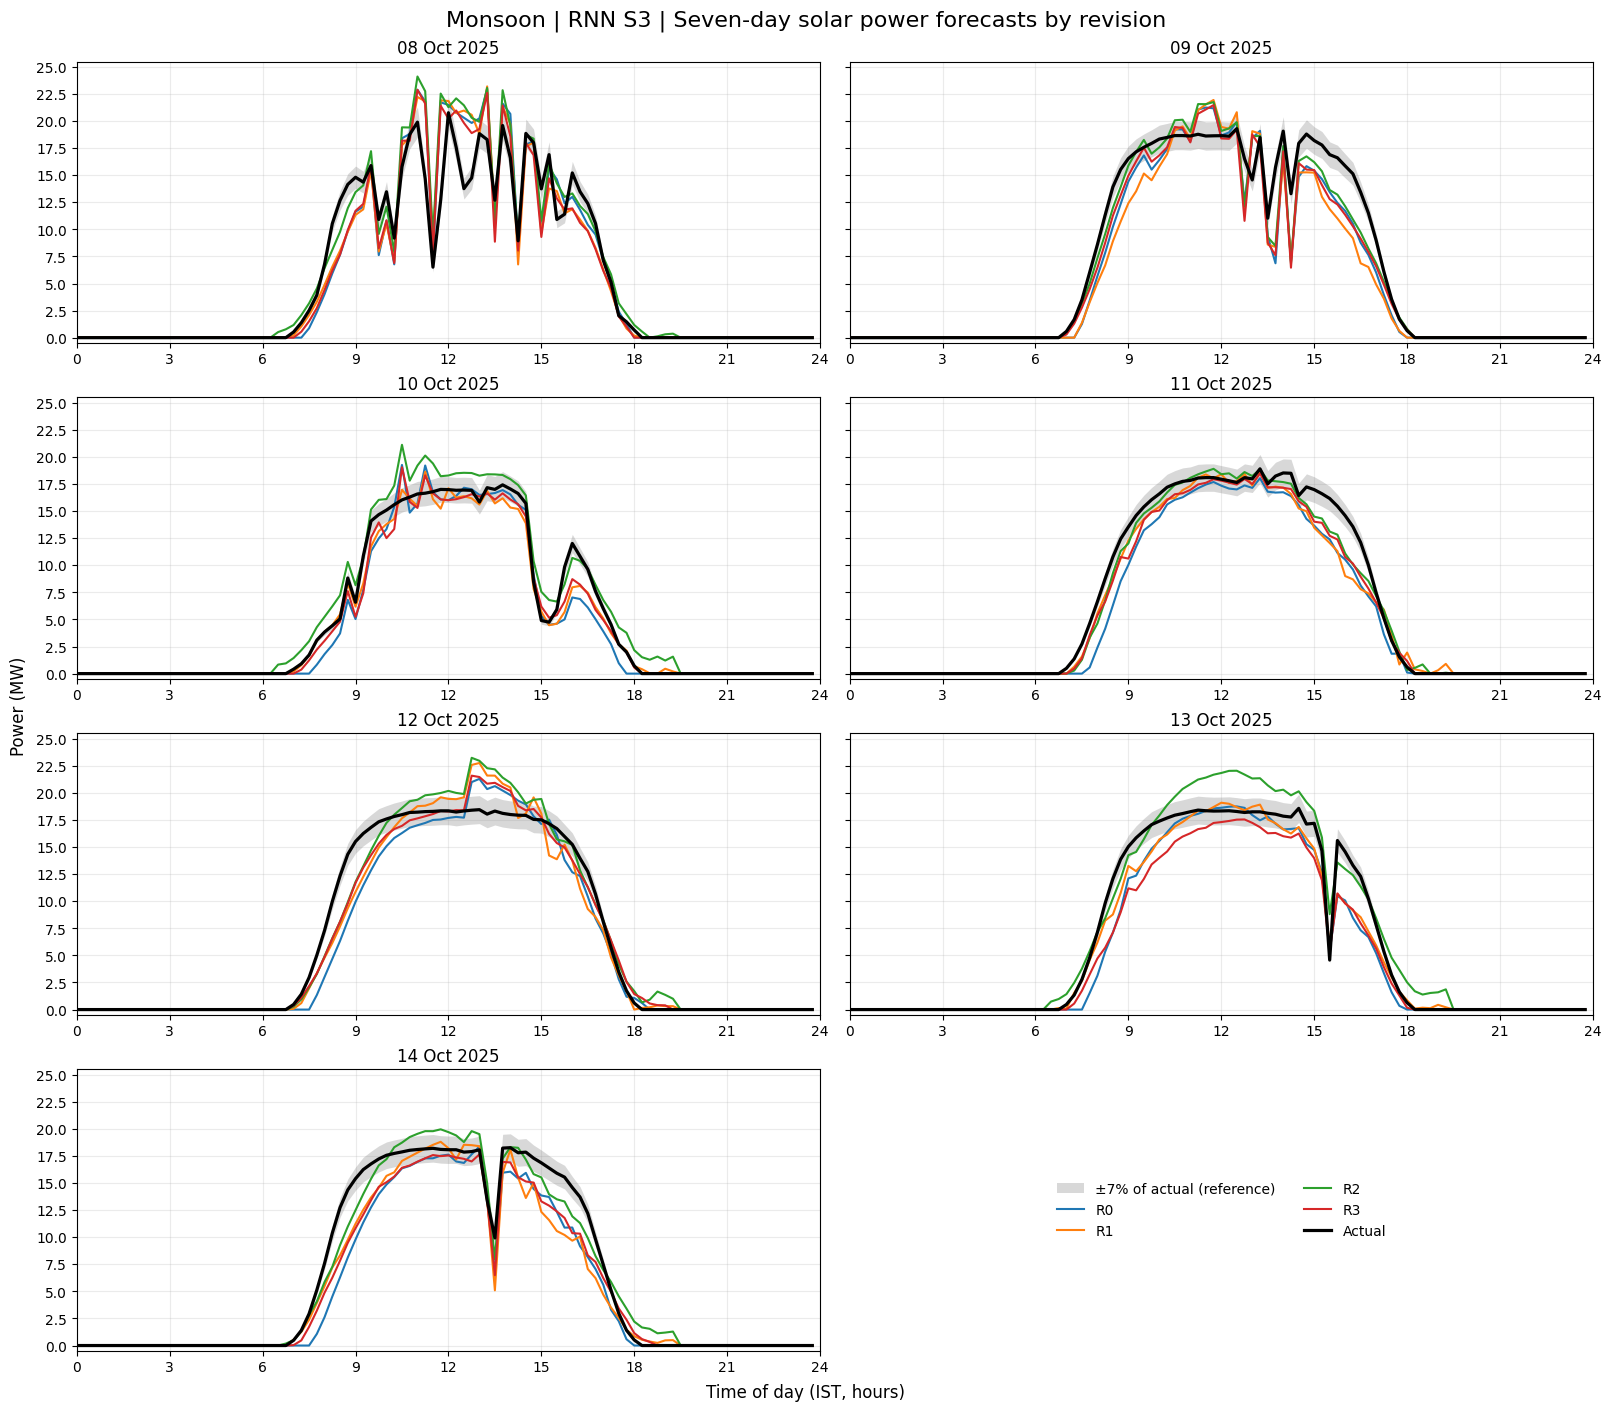

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEASON = "Monsoon"
SCENARIO = "S3"
BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1

# The ±7% band below is relative to actual power.
# It is a visual reference, not the capacity-based DSM threshold.


# 1. Verify the seven test dates and all four revisions.
test_dates_array = pd.DatetimeIndex(
    pd.to_datetime(dates_test)
).normalize()
test_labels = np.asarray(revision_labels_test)

test_days = pd.date_range("2025-10-08", "2025-10-14", freq="D")
revision_order = ["R0", "R1", "R2", "R3"]

expected_pairs = pd.MultiIndex.from_product(
    [test_days, revision_order]
)
observed_pairs = pd.MultiIndex.from_arrays(
    [test_dates_array, test_labels]
)

if not observed_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError(
        "Expected exactly one R0–R3 sample per day for October 8–14, 2025."
    )

if X_test_scaled.shape != (28, 82, 7):
    raise ValueError("Expected historical inputs with shape (28, 82, 7).")

if X_future_test_selected.shape != (28, 96, 5):
    raise ValueError("Expected selected future inputs with shape (28, 96, 5).")

y_actual = np.asarray(y_test, dtype=np.float64).copy()

if y_actual.shape != (28, 96):
    raise ValueError("Expected actual power with shape (28, 96).")

if not all(
    np.isfinite(values).all()
    for values in (X_test_scaled, X_future_test_selected, y_actual)
):
    raise ValueError("Inputs or actual targets contain nonfinite values.")

for day in test_days:
    day_actual = y_actual[test_dates_array == day]
    if not np.allclose(
        day_actual, day_actual[0], atol=1e-6, rtol=0
    ):
        raise ValueError(f"{day.date()}: actual power differs across revisions.")


# 2. Predict using the trained Monsoon S3 model.
# This cell does not retrain.
predictions_scaled = model.predict(
    [X_test_scaled, X_future_test_selected],
    batch_size=16,
    verbose=0,
)

if (
    predictions_scaled.shape != y_actual.shape
    or not np.isfinite(predictions_scaled).all()
):
    raise ValueError("Invalid scaled predictions.")

y_test_pred_raw = scaler.inverse_transform(
    predictions_scaled.reshape(-1, 1)
).reshape(y_actual.shape)

if not np.isfinite(y_test_pred_raw).all():
    raise ValueError("Inverse-scaled predictions contain nonfinite values.")


# 3. Reuse the training-only night-mask source from sample creation.
night_source = np.asarray(nightmask_training_power, dtype=np.float64)

if night_source.shape != (86, 96) or not np.isfinite(night_source).all():
    raise ValueError(
        "Expected night-mask power from all 86 complete Monsoon training days."
    )

active_fraction = (night_source > ACTIVE_THRESHOLD_MW).mean(axis=0)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)

y_test_pred = np.maximum(y_test_pred_raw, 0.0)
y_test_pred[:, night_mask] = 0.0

# Compatibility with later export cells.
y_pred_raw = y_test_pred_raw
y_pred = y_test_pred

print("Forecast target dates: October 8–14, 2025")
print("7 test days × 4 revisions = 28 profiles, each with 96 blocks.")
print(f"Training-derived night blocks: {len(night_blocks)} / 96")


# 4. Metrics and counts within ±7% of actual power.
rows = []

for revision in ["Overall", *revision_order]:
    mask = (
        np.ones(len(y_actual), dtype=bool)
        if revision == "Overall"
        else test_labels == revision
    )

    actual = y_actual[mask].ravel()
    predicted = y_pred[mask].ravel()

    tolerance = BAND_FRACTION * np.abs(actual)
    inside = np.abs(predicted - actual) <= tolerance + 1e-6
    active = actual > ACTIVE_THRESHOLD_MW

    rows.append({
        "Revision": revision,
        "MAE (MW)": mean_absolute_error(actual, predicted),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": (
            r2_score(actual, predicted)
            if np.var(actual) > 0
            else np.nan
        ),
        "Inside / all": f"{inside.sum()}/{inside.size}",
        "Inside all (%)": 100 * inside.mean(),
        "Inside / active": f"{(inside & active).sum()}/{active.sum()}",
        "Inside active (%)": (
            100 * inside[active].mean() if active.any() else np.nan
        ),
    })

test_metrics = pd.DataFrame(rows)

print(f"\n{SEASON} {SCENARIO} — postprocessed test metrics")
print("Band coverage uses ±7% of actual power, not the DSM threshold.")
print(test_metrics.round(4).to_string(index=False))


# 5. Plot all seven days.
hours = np.arange(96) / 4
colors = {
    "R0": "tab:blue",
    "R1": "tab:orange",
    "R2": "tab:green",
    "R3": "tab:red",
}

lower_bands = y_actual - BAND_FRACTION * np.abs(y_actual)
upper_bands = y_actual + BAND_FRACTION * np.abs(y_actual)

minimum = min(float(lower_bands.min()), float(y_pred.min()), 0.0)
maximum = max(float(upper_bands.max()), float(y_pred.max()))

# Keep zero curves and any negative measurements visible.
y_lower = minimum - 0.5
y_upper = max(20.0, np.ceil(maximum / 2.5) * 2.5) + 0.5

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 14),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
axes = axes.ravel()

for ax, day in zip(axes, test_days):
    day_mask = np.asarray(test_dates_array == day)
    day_indices = np.flatnonzero(day_mask)
    actual = y_actual[day_indices[0]]
    tolerance = BAND_FRACTION * np.abs(actual)

    ax.fill_between(
        hours,
        actual - tolerance,
        actual + tolerance,
        color="gray",
        alpha=0.30,
        linewidth=0,
        label="±7% of actual (reference)",
        zorder=1,
    )

    for revision in revision_order:
        index = np.flatnonzero(
            day_mask & (test_labels == revision)
        )[0]

        ax.plot(
            hours,
            y_pred[index],
            color=colors[revision],
            linewidth=1.5,
            label=revision,
            zorder=2,
        )

    ax.plot(
        hours,
        actual,
        color="black",
        linewidth=2.3,
        label="Actual",
        zorder=3,
    )

    ax.set_title(day.strftime("%d %b %Y"))
    ax.set_xlim(0, 24)
    ax.set_ylim(y_lower, y_upper)
    ax.set_xticks(np.arange(0, 25, 3))
    ax.yaxis.set_major_locator(MultipleLocator(2.5))
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)

axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(
    handles, labels,
    loc="center",
    ncol=2,
    frameon=False,
)

fig.suptitle(
    "Monsoon | RNN S3 | Seven-day solar power forecasts by revision",
    fontsize=16,
)
fig.supxlabel("Time of day (IST, hours)")
fig.supylabel("Power (MW)")

plt.show()

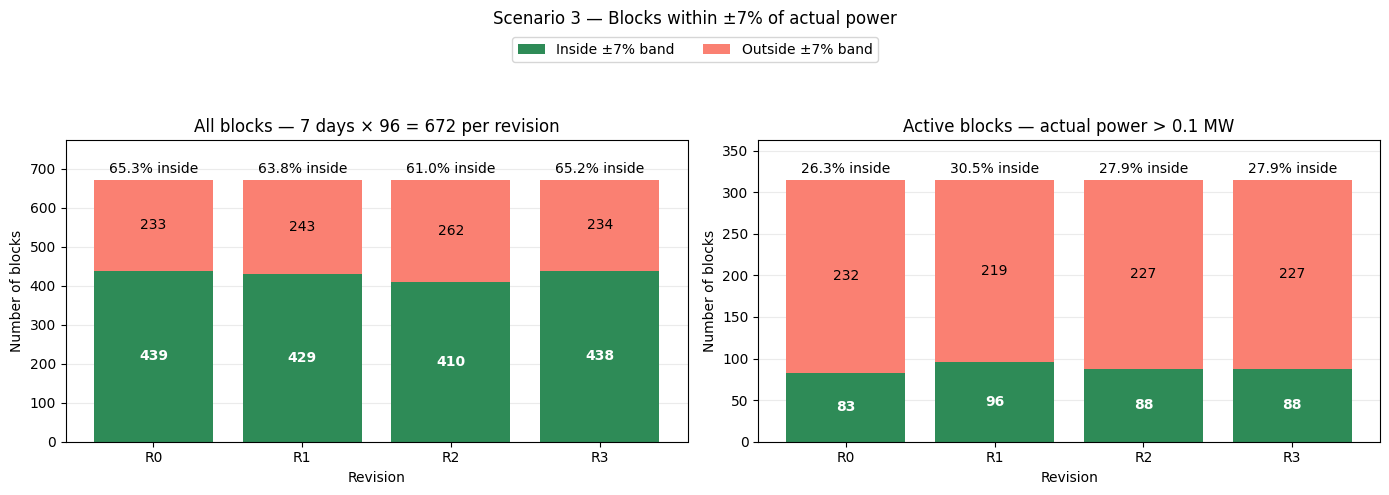

In [10]:
# Uses existing y_test, y_test_pred, and test_labels.
revisions = list(REVISION_LENGTHS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, active_only in zip(axes, [False, True]):
    inside_counts = []
    outside_counts = []

    for revision in revisions:
        revision_mask = test_labels == revision

        actual = y_test[revision_mask].ravel()
        predicted = y_test_pred[revision_mask].ravel()

        eligible = (
            actual > ACTIVE_THRESHOLD_MW
            if active_only
            else np.ones(actual.shape, dtype=bool)
        )

        inside = (
            np.abs(predicted - actual)
            <= BAND_FRACTION * np.abs(actual) + 1e-6
        )

        inside_counts.append(int(np.sum(inside & eligible)))
        outside_counts.append(int(np.sum(~inside & eligible)))

    inside_counts = np.asarray(inside_counts)
    outside_counts = np.asarray(outside_counts)
    totals = inside_counts + outside_counts

    ax.bar(
        revisions, inside_counts,
        color="seagreen", label="Inside ±7% band",
    )
    ax.bar(
        revisions, outside_counts,
        bottom=inside_counts,
        color="salmon", label="Outside ±7% band",
    )

    for i, (inside, outside, total) in enumerate(
        zip(inside_counts, outside_counts, totals)
    ):
        if inside:
            ax.text(
                i, inside / 2, str(inside),
                ha="center", va="center", color="white",
                fontweight="bold",
            )
        if outside:
            ax.text(
                i, inside + outside / 2, str(outside),
                ha="center", va="center",
            )
        if total:
            ax.text(
                i, total + max(totals.max(), 1) * 0.025,
                f"{100 * inside / total:.1f}% inside",
                ha="center", fontsize=10,
            )

    ax.set_title(
        "Active blocks — actual power > 0.1 MW"
        if active_only else
        "All blocks — 7 days × 96 = 672 per revision"
    )
    ax.set_xlabel("Revision")
    ax.set_ylabel("Number of blocks")
    ax.set_ylim(0, max(int(totals.max()), 1) * 1.15)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.94), ncol=2,
)
fig.suptitle("Scenario 3 — Blocks within ±7% of actual power")
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

SEASON = "Monsoon"
scenario = "S3"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
prediction_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Predictions"
)
prediction_dir.mkdir(parents=True, exist_ok=True)

# Fixed filename: overwrite the previous Monsoon S3 predictions.
results_path = prediction_dir / f"{SEASON}_Daily_RNN_{scenario}.csv"


# 1. Verify all seven target days and four revisions.
dates = pd.DatetimeIndex(pd.to_datetime(dates_test)).normalize()
labels = np.asarray(revision_labels_test)

revision_names = {
    "R0": "Rev0",
    "R1": "Rev1",
    "R2": "Rev2",
    "R3": "Rev3",
}
test_days = pd.date_range("2025-10-08", "2025-10-14", freq="D")

expected = pd.MultiIndex.from_product(
    [test_days, list(revision_names)]
)
observed = pd.MultiIndex.from_arrays([dates, labels])

if not observed.sort_values().equals(expected.sort_values()):
    raise ValueError(
        "Expected exactly one R0–R3 forecast per day "
        "for October 8–14, 2025."
    )

if X_test_scaled.shape != (28, 82, 7):
    raise ValueError("Expected history inputs with shape (28, 82, 7).")

if X_future_test_selected.shape != (28, 96, 5):
    raise ValueError("Expected future inputs with shape (28, 96, 5).")

if not all(
    np.isfinite(values).all()
    for values in (X_test_scaled, X_future_test_selected)
):
    raise ValueError("Test inputs contain nonfinite values.")


# 2. Predict using the trained Monsoon S3 model.
# No retraining occurs in this cell.
predicted_scaled = model.predict(
    [X_test_scaled, X_future_test_selected],
    batch_size=16,
    verbose=0,
)

y_actual = np.asarray(y_test, dtype=np.float64).copy()

if predicted_scaled.shape != (28, 96) or y_actual.shape != (28, 96):
    raise ValueError("Expected actual and forecast shapes of (28, 96).")

if not np.isfinite(predicted_scaled).all():
    raise ValueError("Scaled predictions contain nonfinite values.")

y_test_pred_raw = scaler.inverse_transform(
    predicted_scaled.reshape(-1, 1)
).reshape(28, 96)

if not (
    np.isfinite(y_actual).all()
    and np.isfinite(y_test_pred_raw).all()
):
    raise ValueError("Actual or forecast power contains nonfinite values.")


# 3. Use all 86 complete Monsoon training profiles for the night mask.
training_profiles = np.asarray(
    nightmask_training_power, dtype=np.float64
)

if (
    training_profiles.shape != (86, 96)
    or not np.isfinite(training_profiles).all()
):
    raise ValueError(
        "Expected 86 complete Monsoon training profiles, each with 96 blocks."
    )

active_fraction = (training_profiles > 0.1).mean(axis=0)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)

y_test_pred = np.maximum(y_test_pred_raw, 0.0)
y_test_pred[:, night_mask] = 0.0

# Compatibility with later metrics and plotting cells.
y_pred_raw = y_test_pred_raw
y_pred = y_test_pred

for day in test_days:
    day_actual = y_actual[dates == day]
    if not np.allclose(
        day_actual, day_actual[0], atol=1e-6, rtol=0.0
    ):
        raise ValueError(f"{day.date()}: actuals differ across revisions.")


# 4. Prepare the replacement CSV with the same four columns as S1/S2.
block_offsets = pd.to_timedelta(15 * np.arange(96), unit="min")

predictions_df = pd.DataFrame({
    "Revision": np.repeat(
        [revision_names[r] for r in labels], 96
    ),
    "Target_Time": (
        dates.repeat(96)
        + np.tile(block_offsets.to_numpy(), len(dates))
    ),
    "Actual_MW": y_actual.ravel(),
    "Forecast_MW": y_test_pred.ravel(),
}).sort_values(
    ["Revision", "Target_Time"],
    ignore_index=True,
)


def save_predictions():
    """Replace the old S3 CSV after writing the new table completely."""
    temporary_path = results_path.with_name(
        f"{results_path.stem}_pending.csv"
    )

    predictions_df.to_csv(
        temporary_path,
        index=False,
        date_format="%Y-%m-%d %H:%M",
    )

    try:
        temporary_path.replace(results_path)
    except PermissionError:
        raise PermissionError(
            f"Cannot overwrite {results_path}. Close it in Excel, "
            "then run save_predictions(). No retraining is needed. "
            f"New predictions are preserved at {temporary_path}."
        ) from None

    print(f"{SEASON} — {scenario}")
    print("Test target dates: October 8–14, 2025")
    print(f"Training-derived night blocks: {len(night_blocks)} / 96")
    print(f"Saved/overwritten {len(predictions_df):,} prediction rows:")
    print(results_path)


save_predictions()

Monsoon — S3
Test target dates: October 8–14, 2025
Training-derived night blocks: 44 / 96
Saved/overwritten 2,688 prediction rows:
C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Monsoon\Predictions\Monsoon_Daily_RNN_S3.csv
